# WTI Crude-Oil Forecasting — Demo

## 1. Setup

In [13]:
import sys
from pathlib import Path

# Make 'src' importable whether this runs from the repo root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt

from src.data import build_dataset, coverage, weekly_history, SPLITS, HORIZON

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 2. Load data

In [14]:
daily, weekly = build_dataset(save=True)   # also writes data/processed/daily.csv and weekly.csv

print(f"{len(daily):,} trading days, {daily.index.min().date()} to {daily.index.max().date()}")
daily[daily["usable"]].head()

4,484 trading days, 2009-01-02 to 2026-10-20


,wti_raw,wti,wti_filled,brent,f1,f2,f3,f4,weekly_week_end,crude_production,refinery_crude_input,refinery_utilization,commercial_crude_stocks,crude_net_imports,target_date,wti_target,split,usable
date,,,,,,,,,,,,,,,,,,
2010-01-04,81.52,81.52,False,79.05,81.51,82.12,82.65,83.12,2009-12-25,5512.0,13879,80.3,307969,7995.0,2010-02-02,77.21,train,True
2010-01-05,81.74,81.74,False,79.27,81.77,82.41,82.99,83.52,2009-12-25,5512.0,13879,80.3,307969,7995.0,2010-02-03,76.96,train,True
2010-01-06,83.12,83.12,False,80.14,83.18,83.75,84.31,84.86,2010-01-01,5507.0,13792,79.9,306626,8323.0,2010-02-04,73.13,train,True
2010-01-07,82.60,82.60,False,80.57,82.66,83.19,83.75,84.29,2010-01-01,5507.0,13792,79.9,306626,8323.0,2010-02-05,71.15,train,True
2010-01-08,82.74,82.74,False,80.06,82.75,83.30,83.87,84.47,2010-01-01,5507.0,13792,79.9,306626,8323.0,2010-02-08,71.87,train,True


**Table organization**

- **Daily:** WTI spot (the target), Brent spot, and NYMEX futures contracts 1-4. Short gaps are filled from the past only.
- **Weekly:** crude production, refinery crude input, refinery utilization, commercial crude stocks, and crude net imports. Each value enters on the date EIA *released* it (the Wednesday after the week ends, later in holiday weeks), never earlier, so there is no look-ahead.
- **Target:** `wti_target` is the WTI spot price 20 trading days after each date. A row is `usable` only if its target is observed and falls in the same split, so no target leaks across a split boundary.

**Known data issues**

- The EIA stopped publishing data after **2024-04-05** so the futures columns are empty for most of the validation period (Jan. 2024 - Aug. 2025) and all of test (Sept. 2025 - Aug. 2026).
- There is a major outlier where WTI spot was **-$36.98 on 2020-04-20**.
- EIA's WTI spot series is missing about 38 trading days in April-July 2011. Currently, inputs are filled from the past on those days and the target is left missing.

In [15]:
coverage(daily)

,first,last,missing_since_2010
wti,2009-01-02,2026-10-20,0.0%
brent,2009-01-02,2026-10-20,0.0%
f1,2009-01-02,2024-04-05,15.0%
f2,2009-01-02,2024-04-05,15.0%
f3,2009-01-02,2024-04-05,15.0%
f4,2009-01-02,2024-04-05,15.0%
crude_production,2009-01-02,2026-10-20,0.0%
refinery_crude_input,2009-01-02,2026-10-20,0.0%
refinery_utilization,2009-01-02,2026-10-20,0.0%
commercial_crude_stocks,2009-01-02,2026-10-20,0.0%


In [16]:
# Forecast origins per split, and how many have an observed, same-split target
daily.groupby("split")["usable"].agg(rows="size", usable="sum").reindex(list(SPLITS))

,rows,usable
split,,
train,3533,3441
val,415,395
test,249,229
live,35,15


In [17]:
# What the models will see for the weekly inputs: the last 12 weeks released by the latest date
weekly_history(weekly, daily.index.max())

,release_date,crude_production,refinery_crude_input,refinery_utilization,commercial_crude_stocks,crude_net_imports
week_end,,,,,,
2026-07-24,2026-07-29,13796.0,17336,97.2,404508,2216.0
2026-07-31,2026-08-05,13804.0,17153,96.5,406987,2513.0
2026-08-07,2026-08-12,13805.0,17179,96.2,424410,4281.0
2026-08-14,2026-08-19,13830.0,17395,97.2,428815,2527.0
2026-08-21,2026-08-26,13843.0,17393,97.4,428910,2366.0
2026-08-28,2026-09-02,13862.0,17496,98.0,424460,2287.0
2026-09-04,2026-09-10,13947.0,17586,97.8,424069,3407.0
2026-09-11,2026-09-16,13944.0,17330,96.8,423429,2227.0
2026-09-18,2026-09-23,13939.0,16811,94.0,426398,2596.0


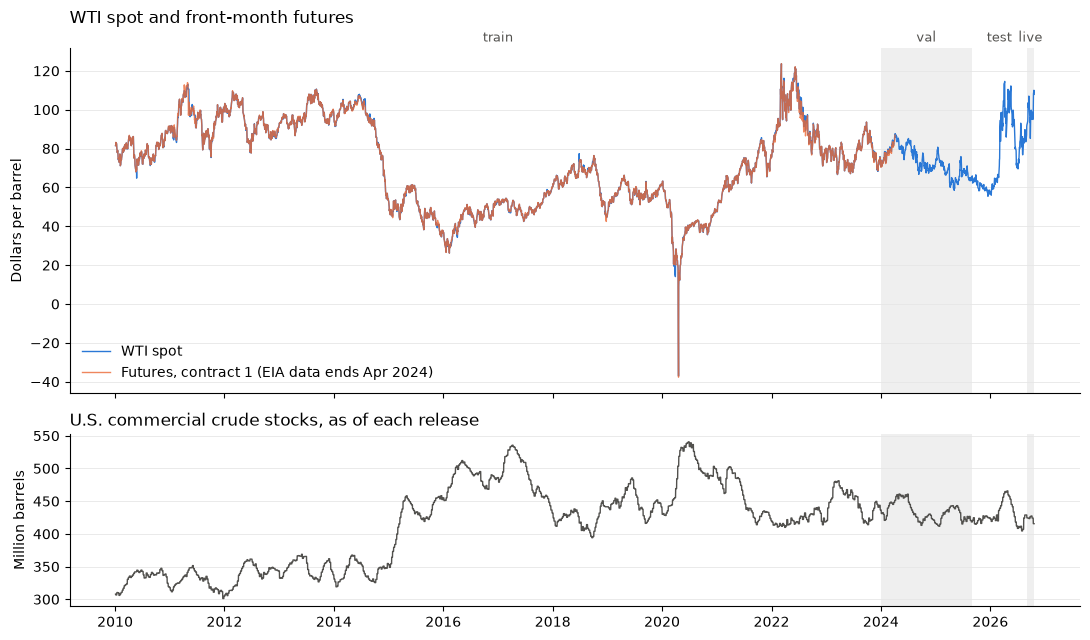

In [18]:
plot_data = daily.loc["2010":]
end = daily.index.max()

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True,
                              gridspec_kw={"height_ratios": [2, 1]})

ax.plot(plot_data.index, plot_data["wti"], lw=1, color="#2a78d6", label="WTI spot")
ax.plot(plot_data.index, plot_data["f1"], lw=1, color="#eb6834", alpha=0.8,
        label="Futures, contract 1 (EIA data ends Apr 2024)")

# Shade the evaluation periods and label every split
for i, (name, (start, stop)) in enumerate(SPLITS.items()):
    start, stop = pd.Timestamp(start), min(pd.Timestamp(stop), end)
    if i % 2 == 1:
        for a in (ax, ax2):
            a.axvspan(start, stop, color="0.5", alpha=0.12, lw=0)
    ax.text(start + (stop - start) / 2, 1.01, name, transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", fontsize=9, color="#52514e")

ax.set_ylabel("Dollars per barrel")
ax.set_title("WTI spot and front-month futures", loc="left", pad=18)
ax.legend(loc="lower left", frameon=False)

ax2.plot(plot_data.index, plot_data["commercial_crude_stocks"] / 1000, lw=1, color="#52514e")
ax2.set_ylabel("Million barrels")
ax2.set_title("U.S. commercial crude stocks, as of each release", loc="left")

for a in (ax, ax2):
    a.grid(axis="y", color="0.9", lw=0.6)
    a.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
fig.savefig(ROOT / "results" / "figures" / "wti_overview.png", dpi=150)
plt.show()

## 3. Baselines: persistence and futures

In [ ]:
# TODO

## 4. LSTM forecasts

In [ ]:
# TODO

## 5. LLM forecasts

In [ ]:
# TODO

## 6. Results: MAE, RMSE, disagreement plots

In [ ]:
# TODO